In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("walkrun.csv")
df.head()

,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,2017-6-30,13:51:15:847724020,viktor,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,2017-6-30,13:51:16:246945023,viktor,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,2017-6-30,13:51:16:446233987,viktor,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,2017-6-30,13:51:16:646117985,viktor,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,2017-6-30,13:51:16:846738994,viktor,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


In [3]:
df.shape

(88588, 11)

In [4]:
df.columns

Index(['date', 'time', 'username', 'wrist', 'activity', 'acceleration_x',
       'acceleration_y', 'acceleration_z', 'gyro_x', 'gyro_y', 'gyro_z'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            88588 non-null  object 
 1   time            88588 non-null  object 
 2   username        88588 non-null  object 
 3   wrist           88588 non-null  int64  
 4   activity        88588 non-null  int64  
 5   acceleration_x  88588 non-null  float64
 6   acceleration_y  88588 non-null  float64
 7   acceleration_z  88588 non-null  float64
 8   gyro_x          88588 non-null  float64
 9   gyro_y          88588 non-null  float64
 10  gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 7.4+ MB


In [6]:
df.describe()

,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
count,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000
mean,0.522170,0.500801,-0.074811,-0.562585,-0.313956,0.004160,0.037203,0.022327
std,0.499511,0.500002,1.009299,0.658458,0.486815,1.253423,1.198725,1.914423
min,0.000000,0.000000,-5.350500,-3.299000,-3.753800,-4.430600,-7.464700,-9.480000
25%,0.000000,0.000000,-0.381800,-1.033500,-0.376000,-0.920700,-0.644825,-1.345125
50%,1.000000,1.000000,-0.059500,-0.759100,-0.221000,0.018700,0.039300,0.006900
75%,1.000000,1.000000,0.355500,-0.241775,-0.085900,0.888800,0.733700,1.398200
max,1.000000,1.000000,5.603300,2.668000,1.640300,4.874200,8.498000,11.266200


In [7]:
df.isnull().sum()

date              0
time              0
username          0
wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
# Count activity categories

print(df['activity'].value_counts())

activity
1    44365
0    44223
Name: count, dtype: int64


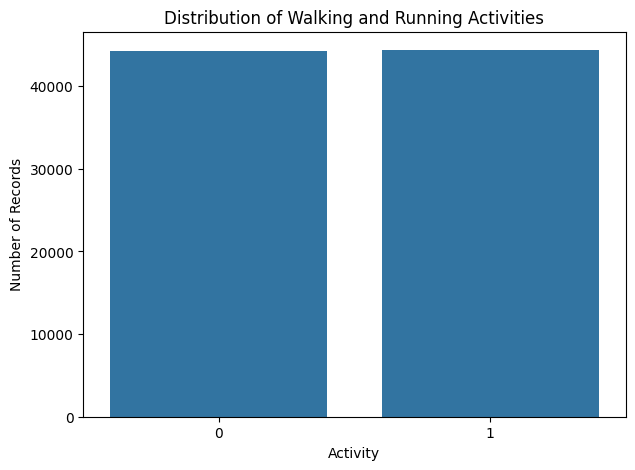

In [10]:
# Activity distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='activity')

plt.title('Distribution of Walking and Running Activities')
plt.xlabel('Activity')
plt.ylabel('Number of Records')

plt.show()

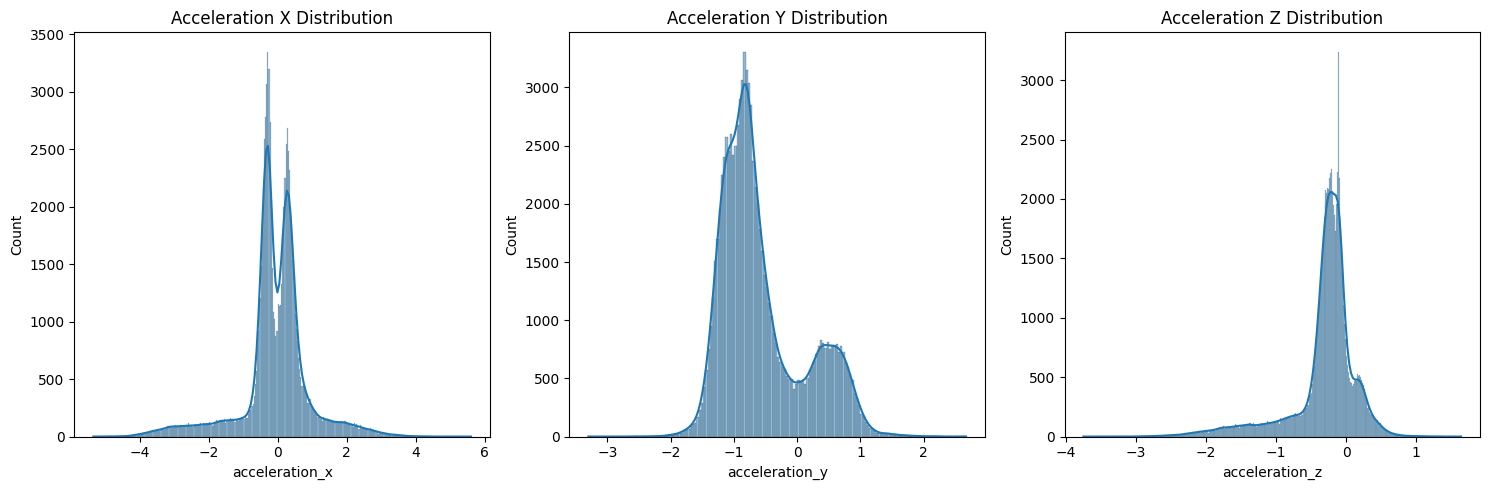

In [11]:
# Distribution of acceleration variables

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['acceleration_x'], kde=True)
plt.title('Acceleration X Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['acceleration_y'], kde=True)
plt.title('Acceleration Y Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['acceleration_z'], kde=True)
plt.title('Acceleration Z Distribution')

plt.tight_layout()
plt.show()

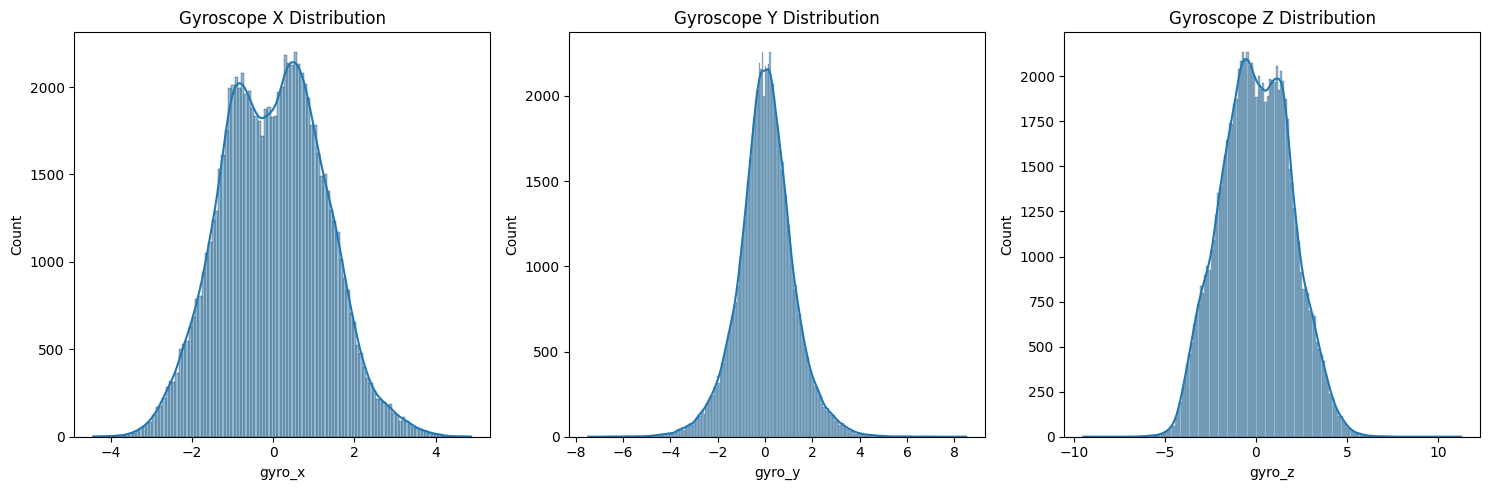

In [12]:
# Distribution of gyroscope variables

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['gyro_x'], kde=True)
plt.title('Gyroscope X Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['gyro_y'], kde=True)
plt.title('Gyroscope Y Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['gyro_z'], kde=True)
plt.title('Gyroscope Z Distribution')

plt.tight_layout()
plt.show()

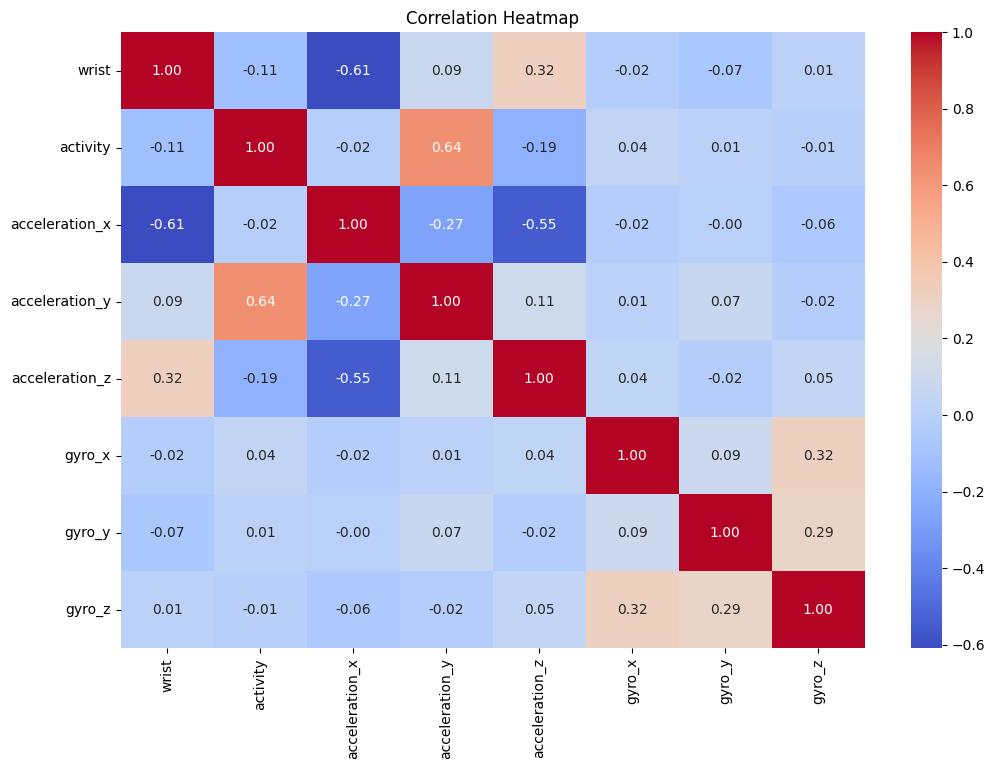

In [13]:
# Correlation heatmap

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## Exploratory Data Analysis – Observations

1. The dataset contains 88,588 records and 11 attributes.

2. The target variable contains two activity categories, represented by 0 and 1.

3. Both activity classes are almost equally distributed, indicating that the dataset is balanced.

4. The acceleration variables show different distribution patterns, indicating variations in movement across the three axes.

5. The gyroscope variables also show variations in rotational movement measurements.

6. The correlation analysis indicates that acceleration_y has the strongest linear relationship with the target variable, with a correlation coefficient of 0.64.

7. Other sensor variables show relatively weak linear correlations with the target variable but may still contribute to predictive performance.

8. Further preprocessing and model evaluation are required to identify the most useful features for classification.

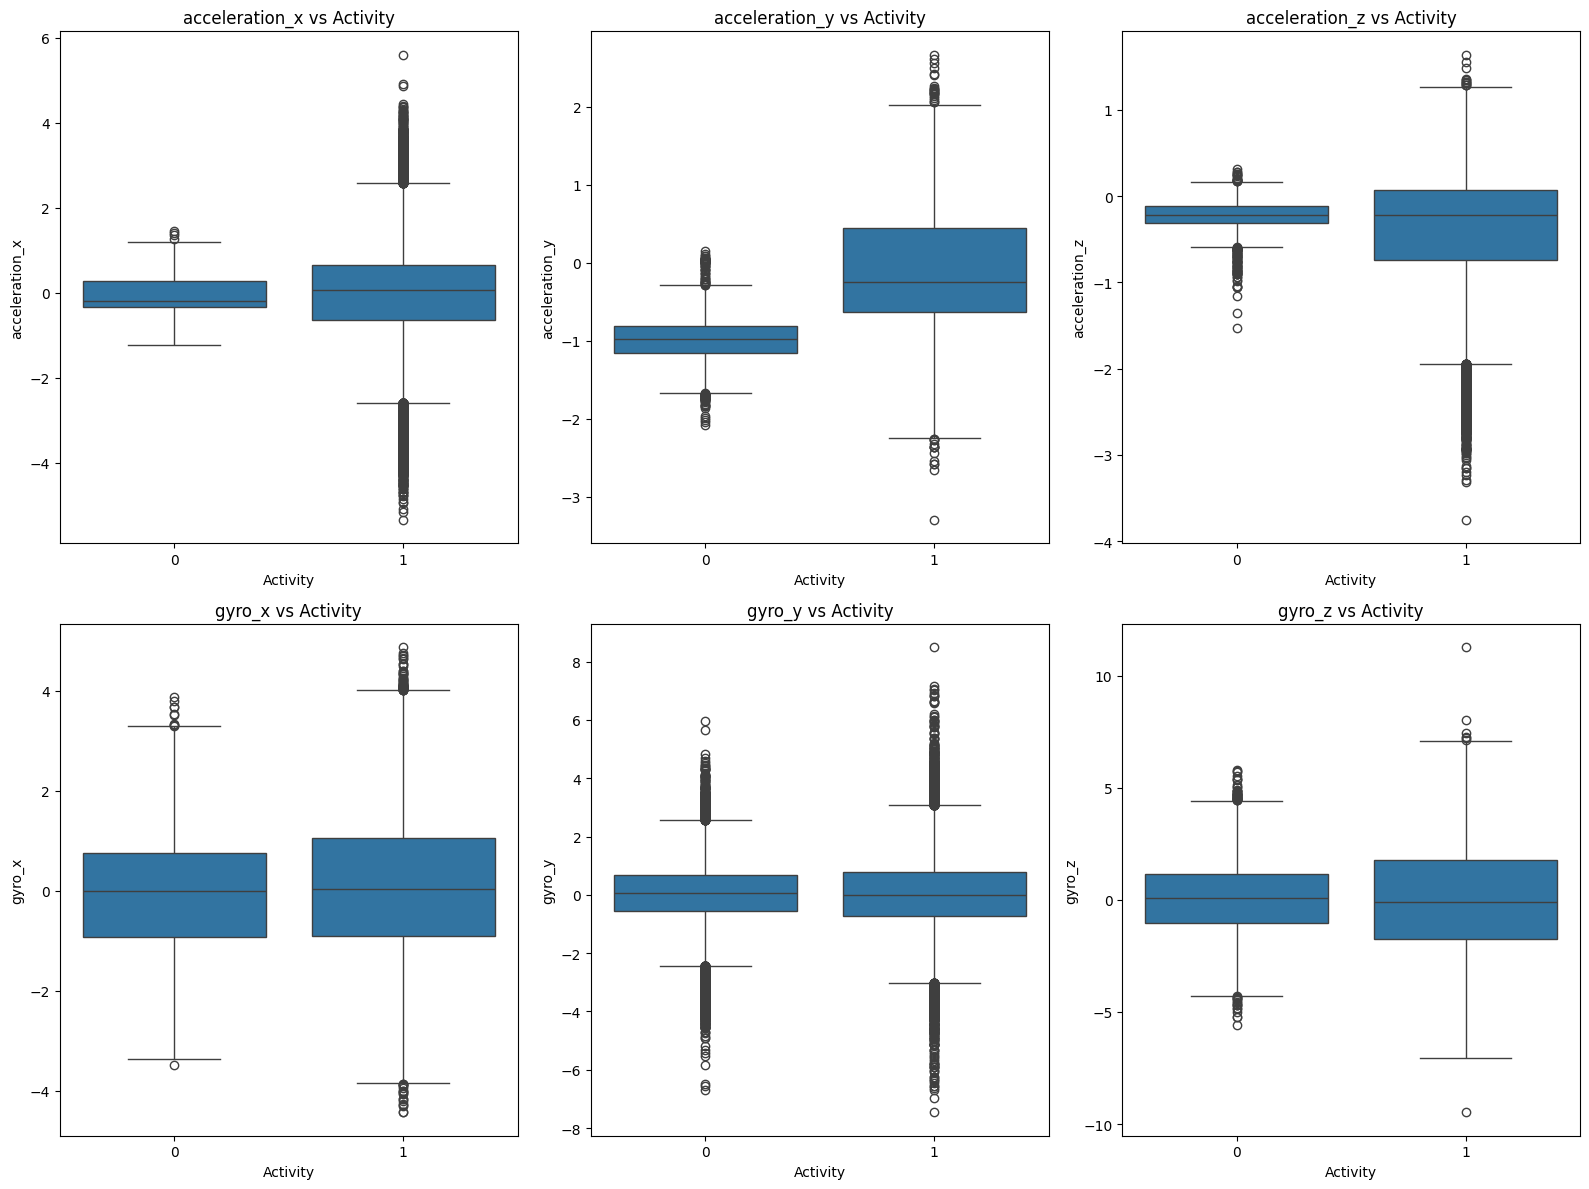

In [14]:
# Comparing sensor readings across activities

features = [
    'acceleration_x',
    'acceleration_y',
    'acceleration_z',
    'gyro_x',
    'gyro_y',
    'gyro_z'
]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x='activity',
        y=feature
    )

    plt.title(f'{feature} vs Activity')
    plt.xlabel('Activity')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

In [15]:
# Mean sensor readings for each activity

df.groupby('activity')[features].mean()

,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
activity,,,,,,
0,-0.056871,-0.984355,-0.220126,-0.047131,0.02273,0.037871
1,-0.092695,-0.142165,-0.407486,0.055288,0.05163,0.006834


## Activity-Wise Sensor Analysis

Boxplots and group-wise statistical analysis were performed to compare sensor readings across the two activity classes.

The following observations were identified:

1. Acceleration X shows differences in distribution and variability between the two activity classes.

2. Acceleration Y demonstrates a noticeable difference in its central tendency across the classes.

3. Acceleration Z shows a wider distribution for Activity 1.

4. Gyroscope X, Y and Z show relatively similar central values, although variations and extreme observations are present.

5. The analysis indicates that acceleration-related features may provide useful information for distinguishing the two activity classes.

6. Several outliers were observed in the sensor measurements. These values will not be removed automatically because they may represent genuine physical movements.

### Conclusion

The activity-wise analysis indicates that acceleration and gyroscope measurements contain potentially useful information for classification. Further preprocessing and model evaluation will be performed to determine their predictive importance.

In [16]:
# Check activity labels

print(df['activity'].value_counts())
print("\nUnique activity values:")
print(df['activity'].unique())

activity
1    44365
0    44223
Name: count, dtype: int64

Unique activity values:
[0 1]


In [17]:
# Creating a copy of the dataset

data = df.copy()

# Selecting relevant columns

data = data[
    [
        'acceleration_x',
        'acceleration_y',
        'acceleration_z',
        'gyro_x',
        'gyro_y',
        'gyro_z',
        'activity'
    ]
]

# Display first five records

data.head()

,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z,activity
0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296,0
1,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269,0
2,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367,0
3,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336,0
4,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922,0


In [18]:
# Independent variables

X = data.drop('activity', axis=1)

# Dependent variable

y = data['activity']

print("Independent Variables Shape:", X.shape)

print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (88588, 6)
Dependent Variable Shape: (88588,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (70870, 6)
Testing Data: (17718, 6)


In [20]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [22]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)
X_train_scaled_df.head()

,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,3.430956,-0.537698,-3.112481,0.504780,-2.010645,-1.499858
1,-1.460232,1.340857,-0.644439,-1.364930,-1.725757,-0.575171
2,0.354850,1.429326,-0.022135,-0.005337,0.033560,-1.082877
3,-0.820485,2.059723,0.408154,-1.017268,1.083492,-0.263792
4,0.086262,-0.635150,0.295699,1.795480,0.540502,0.638397


In [23]:
print("Feature Means:")
print(X_train_scaled_df.mean())

print("\nFeature Standard Deviations:")
print(X_train_scaled_df.std())

Feature Means:
acceleration_x    8.020801e-19
acceleration_y   -4.140739e-17
acceleration_z    1.766581e-16
gyro_x            1.403640e-17
gyro_y            9.223922e-18
gyro_z            2.887488e-17
dtype: float64

Feature Standard Deviations:
acceleration_x    1.000007
acceleration_y    1.000007
acceleration_z    1.000007
gyro_x            1.000007
gyro_y            1.000007
gyro_z            1.000007
dtype: float64


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.854893328818151


Accuracy: 0.854893328818151

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      8845
           1       0.89      0.81      0.85      8873

    accuracy                           0.85     17718
   macro avg       0.86      0.85      0.85     17718
weighted avg       0.86      0.85      0.85     17718


Confusion Matrix:
[[7934  911]
 [1660 7213]]


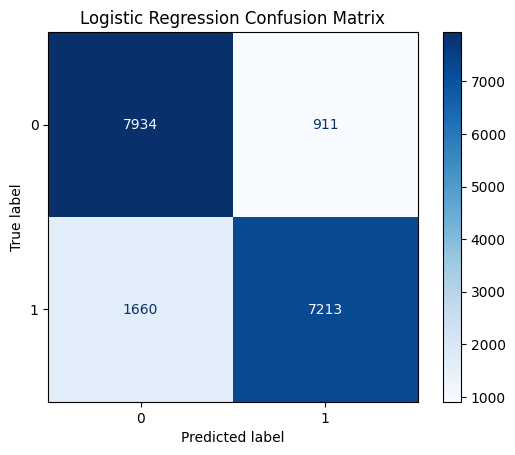

In [25]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

print("\nConfusion Matrix:")
print(cm)

# Visualize Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9898408398239079


In [27]:
from sklearn.svm import SVC

# Initialize SVM
svm_model = SVC(kernel='rbf')

# Train model
svm_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test_scaled)

# Accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.9866802122135682


In [28]:
# Model Comparison

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        lr_accuracy,
        rf_accuracy,
        svm_accuracy
    ]
})

model_comparison['Accuracy (%)'] = (
    model_comparison['Accuracy'] * 100
)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.854893,85.489333
1,Random Forest,0.989841,98.984084
2,SVM,0.986680,98.668021


## Initial Machine Learning Model Comparison

Three classification algorithms were implemented and evaluated:

1. Logistic Regression
2. Random Forest Classifier
3. Support Vector Machine (SVM)

The following accuracy scores were obtained:

- Logistic Regression: 85.49%
- Random Forest: 98.98%
- Support Vector Machine: 98.67%

### Observations

1. Logistic Regression achieved an accuracy of 85.49%, providing a baseline classification performance.

2. Random Forest achieved the highest accuracy of 98.98% among the three initial models.

3. Support Vector Machine achieved an accuracy of 98.67%, performing similarly to Random Forest.

4. Random Forest performed better than Logistic Regression and SVM on the current test split.

5. Further validation using a time-aware splitting strategy is necessary to assess generalisation performance and identify potential data leakage.

### Preliminary Conclusion

Random Forest is the best-performing model based on the initial random train-test evaluation. However, the final production recommendation will depend on additional validation and model evaluation.

In [29]:
from sklearn.neural_network import MLPClassifier

print("MLP Classifier imported successfully!")

MLP Classifier imported successfully!


In [30]:
# Initialize Multi-Layer Perceptron

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    random_state=42
)

print("Neural Network initialized successfully!")

Neural Network initialized successfully!


In [31]:
# Train Neural Network

mlp_model.fit(
    X_train_scaled,
    y_train
)

print("Neural Network Training Completed!")

Neural Network Training Completed!


In [32]:
# Predict test data

y_pred_mlp = mlp_model.predict(X_test_scaled)

print("Neural Network Predictions Completed!")

Neural Network Predictions Completed!


In [33]:
from sklearn.metrics import accuracy_score

mlp_accuracy = accuracy_score(
    y_test,
    y_pred_mlp
)

print("Neural Network Accuracy:", mlp_accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_mlp
    )
)

Neural Network Accuracy: 0.990743876284005

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      8845
           1       0.99      0.99      0.99      8873

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718



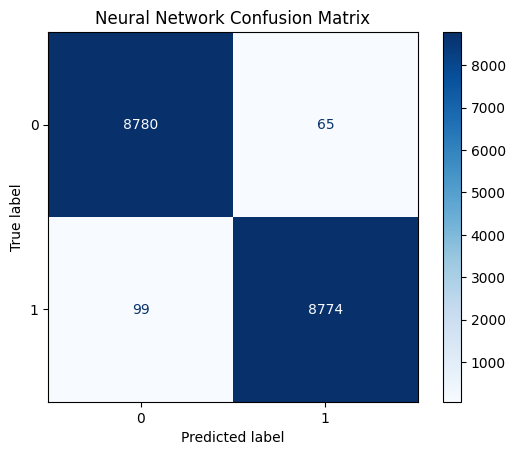

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    cmap='Blues'
)

plt.title("Neural Network Confusion Matrix")

plt.show()

In [35]:
# Final initial model comparison

final_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM',
        'Neural Network'
    ],

    'Accuracy': [
        lr_accuracy,
        rf_accuracy,
        svm_accuracy,
        mlp_accuracy
    ]
})

final_comparison['Accuracy (%)'] = (
    final_comparison['Accuracy'] * 100
)

final_comparison = final_comparison.sort_values(
    by='Accuracy',
    ascending=False
)

final_comparison

,Model,Accuracy,Accuracy (%)
3,Neural Network,0.990744,99.074388
1,Random Forest,0.989841,98.984084
2,SVM,0.986680,98.668021
0,Logistic Regression,0.854893,85.489333


## Model Comparison Report

Four Machine Learning classification algorithms were implemented and evaluated for the Walking Running Classification problem.

The models evaluated were:

1. Logistic Regression
2. Random Forest Classifier
3. Support Vector Machine (SVM)
4. Multi-Layer Perceptron Neural Network (MLP)

### Model Performance

| Model | Accuracy |
|---|---:|
| Logistic Regression | 85.49% |
| Random Forest | 98.98% |
| SVM | 98.67% |
| Neural Network | 99.07% |

### Observations

1. Logistic Regression achieved an accuracy of 85.49%.
2. Random Forest achieved an accuracy of 98.98%.
3. SVM achieved an accuracy of 98.67%.
4. The Multi-Layer Perceptron Neural Network achieved the highest accuracy of 99.07%.

### Preliminary Conclusion

The Neural Network achieved the highest accuracy among the four evaluated models on the current random test split.

Random Forest and SVM also demonstrated strong classification performance.

Further time-aware validation is required before selecting the final production model.

In [36]:
# Check date and time information

print("Date column:")
print(df['date'].head())

print("\nTime column:")
print(df['time'].head())

print("\nDate data type:")
print(df['date'].dtype)

print("\nTime data type:")
print(df['time'].dtype)

Date column:
0    2017-6-30
1    2017-6-30
2    2017-6-30
3    2017-6-30
4    2017-6-30
Name: date, dtype: object

Time column:
0    13:51:15:847724020
1    13:51:16:246945023
2    13:51:16:446233987
3    13:51:16:646117985
4    13:51:16:846738994
Name: time, dtype: object

Date data type:
object

Time data type:
object


In [37]:
# Check date and time availability

print("Unique dates:", df['date'].nunique())

print("\nFirst 10 dates:")
print(df['date'].unique()[:10])

print("\nFirst 10 times:")
print(df['time'].unique()[:10])

Unique dates: 12

First 10 dates:
['2017-6-30' '2017-7-10' '2017-7-11' '2017-7-15' '2017-7-16' '2017-7-17'
 '2017-7-1' '2017-7-2' '2017-7-4' '2017-7-6']

First 10 times:
['13:51:15:847724020' '13:51:16:246945023' '13:51:16:446233987'
 '13:51:16:646117985' '13:51:16:846738994' '13:51:17:46806991'
 '13:51:17:246767997' '13:51:17:446569025' '13:51:17:646152973'
 '13:51:17:846502006']


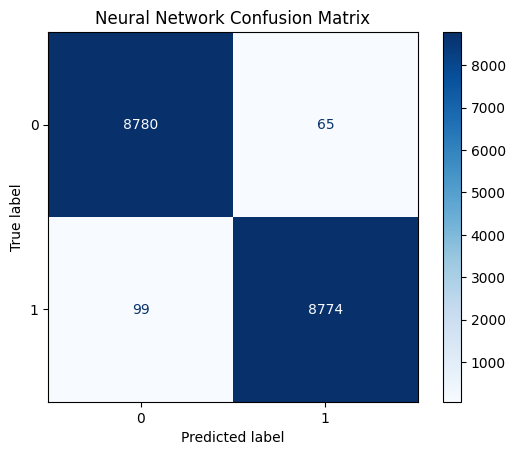

In [38]:
# Neural Network Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    cmap='Blues'
)

plt.title('Neural Network Confusion Matrix')

plt.show()

In [39]:
# Create a copy of original dataset

time_df = df.copy()

# Convert date into datetime format

time_df['date_parsed'] = pd.to_datetime(
    time_df['date'],
    format='%Y-%m-%d',
    errors='coerce'
)

# Convert time format

time_df['time_parsed'] = time_df['time'].astype(str).str.replace(
    r'^(\d{2}:\d{2}:\d{2}):',
    r'\1.',
    regex=True
)

# Combine date and time

time_df['timestamp'] = pd.to_datetime(
    time_df['date_parsed'].dt.strftime('%Y-%m-%d')
    + ' '
    + time_df['time_parsed'],
    format='%Y-%m-%d %H:%M:%S.%f',
    errors='coerce'
)
print(time_df[['date', 'time', 'timestamp']].head())

print("\nMissing timestamps:", time_df['timestamp'].isnull().sum())

        date                time                     timestamp
0  2017-6-30  13:51:15:847724020 2017-06-30 13:51:15.847724020
1  2017-6-30  13:51:16:246945023 2017-06-30 13:51:16.246945023
2  2017-6-30  13:51:16:446233987 2017-06-30 13:51:16.446233987
3  2017-6-30  13:51:16:646117985 2017-06-30 13:51:16.646117985
4  2017-6-30  13:51:16:846738994 2017-06-30 13:51:16.846738994

Missing timestamps: 34867


In [40]:
# Sort dataset chronologically

time_df = time_df.sort_values(
    by='timestamp'
).reset_index(drop=True)

print("First timestamp:")
print(time_df['timestamp'].min())

print("\nLast timestamp:")
print(time_df['timestamp'].max())

First timestamp:
2017-06-30 13:51:15.847724020

Last timestamp:
2017-07-17 20:15:59.884997010


In [41]:
# Activity distribution by date

date_activity = pd.crosstab(
    time_df['date_parsed'].dt.date,
    time_df['activity']
)

print(date_activity)

activity         0     1
date_parsed             
2017-06-30    1241  2751
2017-07-01    2966  1235
2017-07-02     429  3504
2017-07-04     324  2901
2017-07-06    4946  6411
2017-07-07    3280     0
2017-07-09     882  6906
2017-07-10    4337     0
2017-07-11       0  6696
2017-07-15     784  7150
2017-07-16   20480     0
2017-07-17    4554  6811


In [42]:
# Select sensor features

features = [
    'acceleration_x',
    'acceleration_y',
    'acceleration_z',
    'gyro_x',
    'gyro_y',
    'gyro_z'
]

X_time = time_df[features]

y_time = time_df['activity']

# Chronological split

split_index = int(len(time_df) * 0.80)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

print("Training records:", len(X_train_time))
print("Testing records:", len(X_test_time))

print("\nTraining activity distribution:")
print(y_train_time.value_counts())

print("\nTesting activity distribution:")
print(y_test_time.value_counts())

Training records: 70870
Testing records: 17718

Training activity distribution:
activity
0    35436
1    35434
Name: count, dtype: int64

Testing activity distribution:
activity
1    8931
0    8787
Name: count, dtype: int64


In [43]:
# Investigate missing timestamps

invalid_timestamps = time_df[
    time_df['timestamp'].isnull()
]

print("Total invalid timestamps:",
      len(invalid_timestamps))

print("\nFirst 20 invalid date and time values:")

print(
    invalid_timestamps[
        ['date', 'time']
    ].head(20).to_string(index=False)
)

Total invalid timestamps: 34867

First 20 invalid date and time values:
     date              time
2017-6-30  13:52:0:12589991
2017-6-30 13:52:0:213325023
2017-6-30 13:52:0:412436008
2017-6-30 13:52:0:613312005
2017-6-30 13:52:0:813238024
2017-6-30  13:52:1:13520002
2017-6-30 13:52:1:213178992
2017-6-30 13:52:1:412422001
2017-6-30 13:52:1:613179981
2017-6-30 13:52:1:813167989
2017-6-30  13:52:2:13499975
2017-6-30 13:52:2:213227987
2017-6-30 13:52:2:412424981
2017-6-30 13:52:2:613170027
2017-6-30 13:52:2:813582003
2017-6-30  13:52:3:13393998
2017-6-30 13:52:3:213182985
2017-6-30 13:52:3:412434995
2017-6-30 13:52:3:613184988
2017-6-30 13:52:3:813371002


In [44]:
# Check date and time formats

print("Unique date formats:")
print(df['date'].astype(str).str.len().value_counts())

print("\nUnique time string lengths:")
print(df['time'].astype(str).str.len().value_counts())

print("\nMissing original dates:")
print(df['date'].isnull().sum())

print("\nMissing original times:")
print(df['time'].isnull().sum())

Unique date formats:
date
9    54804
8    33784
Name: count, dtype: int64

Unique time string lengths:
time
18    47401
17    32740
16     7743
15      681
14       23
Name: count, dtype: int64

Missing original dates:
0

Missing original times:
0


In [45]:
# Create a fresh copy of original dataset

time_df = df.copy()

# Convert date column

time_df['date_parsed'] = pd.to_datetime(
    time_df['date'],
    format='%Y-%m-%d',
    errors='coerce'
)

# Split time into hour, minute, second and nanoseconds

time_parts = time_df['time'].astype(str).str.split(
    ':',
    expand=True
)

# Ensure four time components exist

print("Time components:", time_parts.shape[1])

# Format seconds to two digits

seconds = time_parts[2].str.zfill(2)

# Ensure fractional seconds have nine digits

nanoseconds = time_parts[3].str.ljust(9, '0')

# Construct corrected time

corrected_time = (
    time_parts[0] + ':' +
    time_parts[1] + ':' +
    seconds + '.' +
    nanoseconds
)

# Combine date and corrected time

time_df['timestamp'] = pd.to_datetime(
    time_df['date_parsed'].dt.strftime('%Y-%m-%d')
    + ' '
    + corrected_time,
    format='%Y-%m-%d %H:%M:%S.%f',
    errors='coerce'
)

# Display results

print("\nTimestamp conversion completed!")

print("Total records:", len(time_df))

print(
    "Invalid timestamps:",
    time_df['timestamp'].isnull().sum()
)

print("\nSample converted timestamps:")

print(
    time_df[['date', 'time', 'timestamp']].head(10)
)

Time components: 4

Timestamp conversion completed!
Total records: 88588
Invalid timestamps: 0

Sample converted timestamps:
        date                time                     timestamp
0  2017-6-30  13:51:15:847724020 2017-06-30 13:51:15.847724020
1  2017-6-30  13:51:16:246945023 2017-06-30 13:51:16.246945023
2  2017-6-30  13:51:16:446233987 2017-06-30 13:51:16.446233987
3  2017-6-30  13:51:16:646117985 2017-06-30 13:51:16.646117985
4  2017-6-30  13:51:16:846738994 2017-06-30 13:51:16.846738994
5  2017-6-30   13:51:17:46806991 2017-06-30 13:51:17.468069910
6  2017-6-30  13:51:17:246767997 2017-06-30 13:51:17.246767997
7  2017-6-30  13:51:17:446569025 2017-06-30 13:51:17.446569025
8  2017-6-30  13:51:17:646152973 2017-06-30 13:51:17.646152973
9  2017-6-30  13:51:17:846502006 2017-06-30 13:51:17.846502006


In [46]:
print("First timestamp:")
print(time_df['timestamp'].min())

print("\nLast timestamp:")
print(time_df['timestamp'].max())

print("\nUnique dates:")
print(time_df['date_parsed'].nunique())

print("\nMissing timestamps:")
print(time_df['timestamp'].isnull().sum())

First timestamp:
2017-06-30 13:51:15.847724020

Last timestamp:
2017-07-17 20:16:03.851119750

Unique dates:
12

Missing timestamps:
0


In [47]:
# Sort records by timestamp

time_df = time_df.sort_values(
    by='timestamp'
).reset_index(drop=True)

print("Chronological sorting completed!")

print(time_df[
    ['date', 'time', 'timestamp', 'activity']
].head())

print("\nLast five records:")

print(time_df[
    ['date', 'time', 'timestamp', 'activity']
].tail())

Chronological sorting completed!
        date                time                     timestamp  activity
0  2017-6-30  13:51:15:847724020 2017-06-30 13:51:15.847724020         0
1  2017-6-30  13:51:16:246945023 2017-06-30 13:51:16.246945023         0
2  2017-6-30  13:51:16:446233987 2017-06-30 13:51:16.446233987         0
3  2017-6-30  13:51:16:646117985 2017-06-30 13:51:16.646117985         0
4  2017-6-30  13:51:16:846738994 2017-06-30 13:51:16.846738994         0

Last five records:
            date               time                     timestamp  activity
88583  2017-7-17  20:16:2:884990990 2017-07-17 20:16:02.884990990         1
88584  2017-7-17  20:16:3:285188019 2017-07-17 20:16:03.285188019         1
88585  2017-7-17  20:16:3:485148012 2017-07-17 20:16:03.485148012         1
88586  2017-7-17  20:16:3:684989988 2017-07-17 20:16:03.684989988         1
88587  2017-7-17   20:16:3:85111975 2017-07-17 20:16:03.851119750         1


In [48]:
# Activity distribution by date

date_activity = pd.crosstab(
    time_df['date_parsed'].dt.date,
    time_df['activity']
)

print(date_activity)

activity         0     1
date_parsed             
2017-06-30    1241  2751
2017-07-01    2966  1235
2017-07-02     429  3504
2017-07-04     324  2901
2017-07-06    4946  6411
2017-07-07    3280     0
2017-07-09     882  6906
2017-07-10    4337     0
2017-07-11       0  6696
2017-07-15     784  7150
2017-07-16   20480     0
2017-07-17    4554  6811


In [49]:
# Sort dataset chronologically

time_df = time_df.sort_values(
    by='timestamp'
).reset_index(drop=True)

print("Chronological sorting completed!")

print("First timestamp:", time_df['timestamp'].iloc[0])

print("Last timestamp:", time_df['timestamp'].iloc[-1])

Chronological sorting completed!
First timestamp: 2017-06-30 13:51:15.847724020
Last timestamp: 2017-07-17 20:16:03.851119750


In [50]:
# Select input features

features = [
    'acceleration_x',
    'acceleration_y',
    'acceleration_z',
    'gyro_x',
    'gyro_y',
    'gyro_z'
]

X_time = time_df[features]

y_time = time_df['activity']

In [51]:
# Chronological 80:20 split

split_index = int(len(time_df) * 0.80)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

print("Training records:", len(X_train_time))

print("Testing records:", len(X_test_time))

print("\nTraining activity distribution:")
print(y_train_time.value_counts())

print("\nTesting activity distribution:")
print(y_test_time.value_counts())

Training records: 70870
Testing records: 17718

Training activity distribution:
activity
1    37554
0    33316
Name: count, dtype: int64

Testing activity distribution:
activity
0    10907
1     6811
Name: count, dtype: int64


In [52]:
print("Training period:")

print(
    time_df['timestamp'].iloc[0],
    "to",
    time_df['timestamp'].iloc[split_index - 1]
)

print("\nTesting period:")

print(
    time_df['timestamp'].iloc[split_index],
    "to",
    time_df['timestamp'].iloc[-1]
)

Training period:
2017-06-30 13:51:15.847724020 to 2017-07-16 15:09:13.784934997

Testing period:
2017-07-16 15:09:13.984892010 to 2017-07-17 20:16:03.851119750


In [53]:
# Activity distribution in training and testing periods

print("Training Activity Distribution:")
print(y_train_time.value_counts(normalize=True) * 100)

print("\nTesting Activity Distribution:")
print(y_test_time.value_counts(normalize=True) * 100)

Training Activity Distribution:
activity
1    52.989982
0    47.010018
Name: proportion, dtype: float64

Testing Activity Distribution:
activity
0    61.558867
1    38.441133
Name: proportion, dtype: float64


In [54]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler_time = StandardScaler()

# Fit on training data
X_train_time_scaled = scaler_time.fit_transform(
    X_train_time
)

# Transform testing data
X_test_time_scaled = scaler_time.transform(
    X_test_time
)

print("Chronological Feature Scaling Completed!")

print("Training Shape:", X_train_time_scaled.shape)
print("Testing Shape:", X_test_time_scaled.shape)

Chronological Feature Scaling Completed!
Training Shape: (70870, 6)
Testing Shape: (17718, 6)


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_time = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_time.fit(
    X_train_time_scaled,
    y_train_time
)

y_pred_lr_time = lr_time.predict(
    X_test_time_scaled
)

lr_time_accuracy = accuracy_score(
    y_test_time,
    y_pred_lr_time
)

print(
    "Chronological Logistic Regression Accuracy:",
    lr_time_accuracy
)

Chronological Logistic Regression Accuracy: 0.8630770967377808


In [56]:
from sklearn.ensemble import RandomForestClassifier

rf_time = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_time.fit(
    X_train_time,
    y_train_time
)

y_pred_rf_time = rf_time.predict(
    X_test_time
)

rf_time_accuracy = accuracy_score(
    y_test_time,
    y_pred_rf_time
)

print(
    "Chronological Random Forest Accuracy:",
    rf_time_accuracy
)

Chronological Random Forest Accuracy: 0.9769725702675246


In [57]:
from sklearn.svm import SVC

svm_time = SVC(
    kernel='rbf'
)

svm_time.fit(
    X_train_time_scaled,
    y_train_time
)

y_pred_svm_time = svm_time.predict(
    X_test_time_scaled
)

svm_time_accuracy = accuracy_score(
    y_test_time,
    y_pred_svm_time
)

print(
    "Chronological SVM Accuracy:",
    svm_time_accuracy
)

Chronological SVM Accuracy: 0.9797945592053279


In [58]:
from sklearn.neural_network import MLPClassifier

mlp_time = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=False,
    random_state=42
)

# Train model

mlp_time.fit(
    X_train_time_scaled,
    y_train_time
)

# Predictions

y_pred_mlp_time = mlp_time.predict(
    X_test_time_scaled
)

# Accuracy

mlp_time_accuracy = accuracy_score(
    y_test_time,
    y_pred_mlp_time
)

print(
    "Chronological Neural Network Accuracy:",
    mlp_time_accuracy
)

Chronological Neural Network Accuracy: 0.9741505813297212


In [59]:
# Chronological Model Comparison

chronological_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM',
        'Neural Network'
    ],

    'Accuracy': [
        lr_time_accuracy,
        rf_time_accuracy,
        svm_time_accuracy,
        mlp_time_accuracy
    ]
})

chronological_comparison['Accuracy (%)'] = (
    chronological_comparison['Accuracy'] * 100
)

chronological_comparison = chronological_comparison.sort_values(
    by='Accuracy',
    ascending=False
)

print(chronological_comparison)

                 Model  Accuracy  Accuracy (%)
2                  SVM  0.979795     97.979456
1        Random Forest  0.976973     97.697257
3       Neural Network  0.974151     97.415058
0  Logistic Regression  0.863077     86.307710


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     10907
           1       0.96      0.99      0.97      6811

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718


SVM Confusion Matrix:
[[10637   270]
 [   88  6723]]


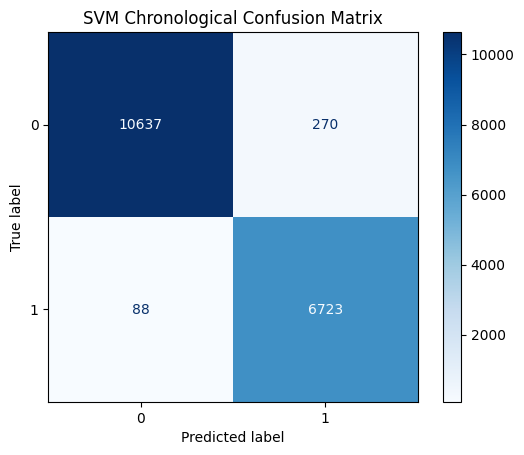

In [60]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Classification report

print("SVM Classification Report:")

print(
    classification_report(
        y_test_time,
        y_pred_svm_time
    )
)

# Confusion matrix

cm_svm = confusion_matrix(
    y_test_time,
    y_pred_svm_time
)

print("\nSVM Confusion Matrix:")

print(cm_svm)

# Visualize confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test_time,
    y_pred_svm_time,
    cmap='Blues'
)

plt.title("SVM Chronological Confusion Matrix")

plt.show()

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     10907
           1       0.95      1.00      0.97      6811

    accuracy                           0.98     17718
   macro avg       0.97      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718



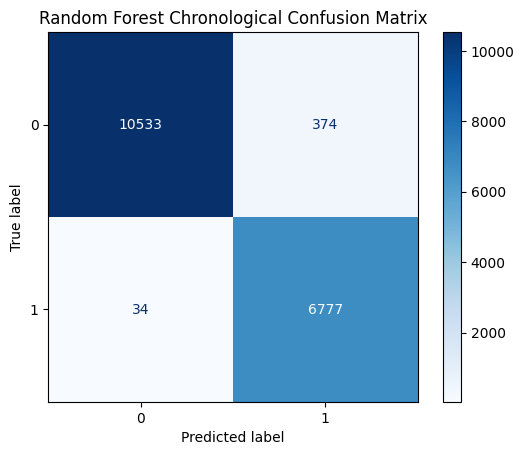

In [61]:
print("Random Forest Classification Report:")

print(
    classification_report(
        y_test_time,
        y_pred_rf_time
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test_time,
    y_pred_rf_time,
    cmap='Blues'
)

plt.title("Random Forest Chronological Confusion Matrix")

plt.show()

Neural Network Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     10907
           1       0.94      0.99      0.97      6811

    accuracy                           0.97     17718
   macro avg       0.97      0.98      0.97     17718
weighted avg       0.98      0.97      0.97     17718



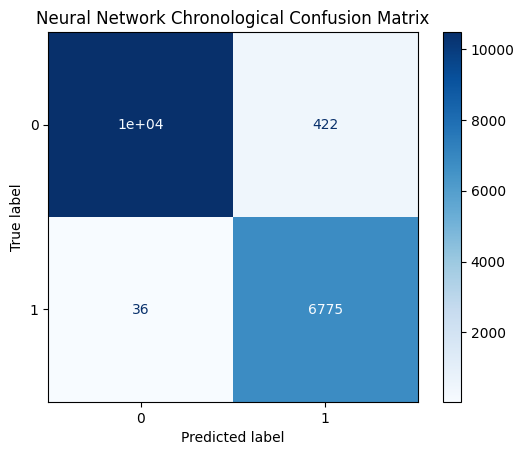

In [62]:
print("Neural Network Classification Report:")

print(
    classification_report(
        y_test_time,
        y_pred_mlp_time
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test_time,
    y_pred_mlp_time,
    cmap='Blues'
)

plt.title("Neural Network Chronological Confusion Matrix")

plt.show()

## Chronological Model Comparison Report

To evaluate the generalisation performance of the classification models, a chronological train-test split was performed.

The earlier 80% of the sensor records were used for training, while the later 20% were used for testing.

Four classification models were evaluated.

### Model Performance

| Model | Chronological Accuracy |
|---|---:|
| Logistic Regression | 86.31% |
| Random Forest | 97.70% |
| SVM | 97.98% |
| Neural Network | 97.42% |

### Observations

1. SVM achieved the highest chronological test accuracy of 97.98%.
2. Random Forest achieved 97.70% accuracy.
3. Neural Network achieved 97.42% accuracy.
4. Logistic Regression achieved 86.31% accuracy.
5. SVM demonstrated the strongest performance on the later-period test dataset.

### Preliminary Conclusion

Based on chronological evaluation, SVM is the leading candidate for the Walking Running Classification problem.

Final model selection will also consider precision, recall, F1-score, computational requirements and practical deployment considerations.

## Model Comparison and Final Model Selection

Three machine learning models—Support Vector Machine (SVM), Random Forest Classifier, and Neural Network—were evaluated using a chronological train-test split. Logistic Regression was also evaluated as a baseline model.

The chronological test results were:

- SVM: 97.98% accuracy
- Random Forest: 97.70% accuracy
- Neural Network: 97.42% accuracy
- Logistic Regression: 86.31% accuracy

The confusion matrices and classification reports were also examined to understand the performance of each model across both activity classes.

The SVM model achieved the highest accuracy of 97.98% and made 358 incorrect predictions out of 17,718 test records. Random Forest made 408 incorrect predictions, while the Neural Network made 458 incorrect predictions.

Based on the chronological test results, SVM is selected as the best-performing model for this experiment. It demonstrated strong classification performance across both classes and achieved the highest overall accuracy.

Random Forest also performed well and can be considered an alternative model.

The selected model is recommended based on the available dataset and evaluation results. Further testing on data collected from different users and devices would be required before considering it ready for real-world production.


In [63]:
df.groupby('activity')[['acceleration_x', 'acceleration_y', 'acceleration_z']].mean()

,acceleration_x,acceleration_y,acceleration_z
activity,,,
0,-0.056871,-0.984355,-0.220126
1,-0.092695,-0.142165,-0.407486


In [64]:
import joblib

# Save the trained SVM model
joblib.dump(svm_time, 'walking_running_svm_model.pkl')

# Save the scaler
joblib.dump(scaler_time, 'walking_running_scaler.pkl')

print("SVM model and scaler saved successfully!")

SVM model and scaler saved successfully!


In [65]:
import os

print(os.path.exists('walking_running_svm_model.pkl'))
print(os.path.exists('walking_running_scaler.pkl'))

True
True


# Walking Running Classification

## 1. Project Introduction

The objective of this project is to analyse sensor data and develop a machine learning model to classify two different physical activities.

The dataset contains readings collected from motion sensors, including acceleration and gyroscope measurements along the X, Y, and Z axes.

Machine learning classification algorithms are used to identify patterns in the sensor readings and predict the corresponding activity.

## 2. Project Objectives

- Understand and analyse the activity sensor dataset.
- Perform data cleaning and exploratory data analysis.
- Visualise sensor readings and identify patterns.
- Train multiple machine learning classification models.
- Compare model performance using evaluation metrics.
- Select the best-performing model.
- Save the final trained model for future predictions.

## 3. Dataset Description

The dataset contains 88,588 records and 11 columns.

The important attributes include:

- Date
- Time
- Username
- Wrist
- Activity
- Acceleration X, Y, Z
- Gyroscope X, Y, Z

The activity column contains two classes: 0 and 1. These are used as the target variable for classification.   

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the structure, quality, and characteristics of the dataset.

### 4.1 Dataset Information

- Total records: 88,588
- Total columns: 11
- Missing values: No missing values were found.
- Duplicate records: No duplicate records were found.
- Target variable: Activity
- Number of activity classes: 2 (0 and 1)

### 4.2 Activity Distribution

The target variable contains two activity classes:

- Activity 0: 44,223 records
- Activity 1: 44,365 records

The dataset has a nearly balanced distribution between the two classes.

### 4.3 Sensor Data Analysis

The acceleration and gyroscope measurements were analysed to understand differences between the two activity classes.

The analysis showed that acceleration measurements, particularly acceleration along the Y-axis, have noticeable differences between the two classes.

### 4.4 Correlation Analysis

A correlation heatmap was created to examine relationships between the numerical variables.

Acceleration Y showed the strongest correlation with the activity variable, with an approximate correlation value of 0.64.

This indicates that acceleration Y may be an important feature for distinguishing between the two activity classes.

### 4.5 Outlier Analysis

Boxplots were used to examine the distribution of sensor readings and identify potential outliers.

Some extreme sensor readings were observed. These values were retained because they may represent genuine physical movements.

## 5. Machine Learning Methodology

### 5.1 Feature Selection

Six sensor features were selected as input variables:

- acceleration_x
- acceleration_y
- acceleration_z
- gyro_x
- gyro_y
- gyro_z

The activity column was selected as the target variable.

### 5.2 Train-Test Split

The dataset was sorted chronologically using the timestamp.

The data was divided into two parts:

- Training data: 80% (70,870 records)
- Testing data: 20% (17,718 records)

A chronological split was used to evaluate model performance on later observations.

### 5.3 Feature Scaling

StandardScaler was used to standardise the sensor features.

The scaler was fitted only on the training data and then applied to the testing data.

### 5.4 Machine Learning Algorithms

Four classification algorithms were trained and evaluated:

1. Logistic Regression
2. Random Forest Classifier
3. Support Vector Machine (SVM)
4. Neural Network (MLP Classifier)

### 5.5 Model Evaluation

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

These metrics helped compare the performance of the classification algorithms.

## 6. Model Performance Comparison

Four machine learning algorithms were evaluated using the chronological test dataset.

The accuracy results are shown below:

| Model | Accuracy |
|---|---:|
| Logistic Regression | 86.31% |
| Random Forest | 97.70% |
| Support Vector Machine (SVM) | 97.98% |
| Neural Network | 97.42% |

### 6.1 Result Analysis

- Logistic Regression achieved an accuracy of 86.31%.
- Random Forest achieved an accuracy of 97.70%.
- SVM achieved the highest accuracy of 97.98%.
- Neural Network achieved an accuracy of 97.42%.

### 6.2 Best Model Selection

Based on the chronological test results, Support Vector Machine (SVM) was selected as the best-performing model.

It achieved the highest accuracy among the four evaluated algorithms.

The SVM model also produced fewer incorrect predictions than Random Forest and Neural Network on the test dataset.

## 7. Challenges Faced

During this project, I faced the following challenges:

1. **Understanding the dataset:** Understanding the meaning of sensor readings and activity labels was an initial challenge.
2. **Data preprocessing:** Converting the date and time columns into valid timestamps required careful handling of different time formats.
3. **Feature scaling:** StandardScaler was used to standardise the sensor features for algorithms such as SVM, Logistic Regression, and Neural Network.
4. **Model comparison:** Different machine learning algorithms produced different results, so their performance had to be compared carefully.
5. **Model selection:** A chronological train-test split was used to evaluate performance on later observations.

## 8. Conclusion

In this project, machine learning techniques were used to classify two activity classes using acceleration and gyroscope sensor readings.

Four classification algorithms were trained and evaluated: Logistic Regression, Random Forest, Support Vector Machine, and Neural Network.

Among these models, Support Vector Machine achieved the highest chronological test accuracy of 97.98%.

Therefore, SVM was selected as the best-performing model for this experiment.

The trained SVM model and its StandardScaler were saved for future use.

## 9. Future Scope

The project can be improved further by:

- Testing the model with data collected from different users.
- Evaluating the model on different wearable devices.
- Exploring additional machine learning algorithms.
- Performing further hyperparameter tuning.
- Developing a real-time activity prediction application.